In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
import warnings

In [2]:
from src.evaluate import calculate_metrics
from src.models.sarima_wrapper import get_sarima_forecast
from src.models.chronos_wrapper import get_chronos_forecast, get_chronos2_forecast
from chronos import ChronosPipeline, Chronos2Pipeline
from tqdm import tqdm
from src.models.lstm import TrafficLSTM

In [3]:
warnings.filterwarnings('ignore')

In [4]:
print("Loading Augmented Traffic Dataset...")
df = pd.read_csv("data/augmented_data.csv")
df["tstamp"] = pd.to_datetime(df["tstamp"])
sectors = df["secteur"].unique()
print(f"Loaded {len(sectors)} unique antenna sectors.")

Loading Augmented Traffic Dataset...


Loaded 86 unique antenna sectors.


In [5]:
context_length = 60
pred_length = 12

In [6]:
X_train_12, y_train_12 = [], []
X_train_1, y_train_1 = [], []
scalers = {}

In [7]:
# Extract training sub-windows for BOTH 12-step and 1-step logic
for sector in sectors:
    series = df[df["secteur"] == sector].sort_values("tstamp")["trafic_mbps"].to_numpy()
    if len(series) < context_length + pred_length:
        continue

    s_min, s_max = series.min(), series.max()
    scaled = 2 * (series - s_min) / (s_max - s_min) - 1 if s_max > s_min else series - s_min
    scalers[sector] = (s_min, s_max)

    train_series = scaled[:-(context_length + pred_length)]
    
    # Generate 12-step windows
    for i in range(0, len(train_series) - context_length - pred_length + 1, 20):
        X_train_12.append(train_series[i : i+context_length])
        y_train_12.append(train_series[i+context_length : i+context_length+pred_length])
        
    # Generate 1-step windows (denser, for rapid optimal representation)
    for i in range(0, len(train_series) - context_length - 1 + 1, 10):
        X_train_1.append(train_series[i : i+context_length])
        y_train_1.append(train_series[i+context_length : i+context_length+1])

In [8]:
X_train_12 = torch.tensor(np.array(X_train_12), dtype=torch.float32).unsqueeze(-1)
y_train_12 = torch.tensor(np.array(y_train_12), dtype=torch.float32)

In [9]:
X_train_1 = torch.tensor(np.array(X_train_1), dtype=torch.float32).unsqueeze(-1)
y_train_1 = torch.tensor(np.array(y_train_1), dtype=torch.float32)

In [10]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'

In [11]:
# Train 12-step LSTM
lstm_model_12 = TrafficLSTM(input_size=1, hidden_layer_size=64, num_layers=2, output_size=pred_length).to(device)
optimizer_12 = torch.optim.Adam(lstm_model_12.parameters(), lr=0.002)
loss_fn = nn.MSELoss()
train_loader_12 = DataLoader(TensorDataset(X_train_12, y_train_12), batch_size=64, shuffle=True)
print("Training PyTorch 12-Step LSTM...")
lstm_model_12.train()
for epoch in range(15):
    for bx, by in train_loader_12:
        optimizer_12.zero_grad()
        loss = loss_fn(lstm_model_12(bx.to(device)), by.to(device))
        loss.backward()
        optimizer_12.step()
lstm_model_12.eval()

Training PyTorch 12-Step LSTM...


TrafficLSTM(
  (lstm): LSTM(1, 64, num_layers=2, batch_first=True, dropout=0.2)
  (linear): Linear(in_features=64, out_features=12, bias=True)
)

In [12]:
# Train 1-step LSTM
lstm_model_1 = TrafficLSTM(input_size=1, hidden_layer_size=64, num_layers=2, output_size=1).to(device)
optimizer_1 = torch.optim.Adam(lstm_model_1.parameters(), lr=0.002)
train_loader_1 = DataLoader(TensorDataset(X_train_1, y_train_1), batch_size=64, shuffle=True)
print("Training PyTorch 1-Step LSTM...")
lstm_model_1.train()
for epoch in range(15):
    for bx, by in train_loader_1:
        optimizer_1.zero_grad()
        loss = loss_fn(lstm_model_1(bx.to(device)), by.to(device))
        loss.backward()
        optimizer_1.step()
lstm_model_1.eval()

Training PyTorch 1-Step LSTM...


TrafficLSTM(
  (lstm): LSTM(1, 64, num_layers=2, batch_first=True, dropout=0.2)
  (linear): Linear(in_features=64, out_features=1, bias=True)
)

In [13]:
print("LSTM Training Complete.")

LSTM Training Complete.


In [14]:
print("Loading Chronos V1 (amazon/chronos-t5-small)...")
pipeline_v1 = ChronosPipeline.from_pretrained("amazon/chronos-t5-small", device_map="cpu", torch_dtype=torch.float32)
print("Loading Chronos 2 (amazon/chronos-2)...")
pipeline_v2 = Chronos2Pipeline.from_pretrained("amazon/chronos-2", device_map="cpu", torch_dtype=torch.float32)

Loading Chronos V1 (amazon/chronos-t5-small)...


`torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/131 [00:00<?, ?it/s]

Loading Chronos 2 (amazon/chronos-2)...


Loading weights:   0%|          | 0/170 [00:00<?, ?it/s]

In [15]:
all_actuals, all_histories, valid_sectors = [], [], []
for sector in sectors:
    series = df[df["secteur"] == sector].sort_values("tstamp")["trafic_mbps"].to_numpy()
    if len(series) < context_length + pred_length:
        continue
    all_actuals.append(series[-pred_length:])
    all_histories.append(series[-(context_length + pred_length):-pred_length])
    valid_sectors.append(sector)

In [16]:
history_tensor_stacked = torch.tensor(np.array(all_histories), dtype=torch.float32)
history_tensors_list = [torch.tensor(h, dtype=torch.float32) for h in all_histories]

In [17]:
print("Running Chronos V1 Multi-Step Batch...")
chronos_v1_preds_12 = get_chronos_forecast(history_tensor_stacked, pred_length=12, model_id="amazon/chronos-t5-small", pipeline=pipeline_v1)
print("Running Chronos 2 Multi-Step Batch...")
chronos_v2_preds_12 = get_chronos2_forecast(history_tensors_list, pred_length=12, pipeline=pipeline_v2)

Running Chronos V1 Multi-Step Batch...


Running Chronos 2 Multi-Step Batch...


In [18]:
print("Running Chronos V1 Single-Step Batch...")
chronos_v1_preds_1 = get_chronos_forecast(history_tensor_stacked, pred_length=1, model_id="amazon/chronos-t5-small", pipeline=pipeline_v1)
print("Running Chronos 2 Single-Step Batch...")
chronos_v2_preds_1 = get_chronos2_forecast(history_tensors_list, pred_length=1, pipeline=pipeline_v2)

Running Chronos V1 Single-Step Batch...


Running Chronos 2 Single-Step Batch...


In [19]:
sarima_rmses_12, lstm_rmses_12, c_v1_rmses_12, c_v2_rmses_12 = [], [], [], []
sarima_pbl_12, lstm_pbl_12, c_v1_pbl_12, c_v2_pbl_12 = [], [], [], []
sarima_pbl90_12, lstm_pbl90_12, c_v1_pbl90_12, c_v2_pbl90_12 = [], [], [], []
sarima_pbl95_12, lstm_pbl95_12, c_v1_pbl95_12, c_v2_pbl95_12 = [], [], [], []

In [20]:
sarima_preds_12_dict, lstm_preds_12_dict = {}, {}

In [21]:
print("Evaluating 12-Step Forecasts...")
for i, sector in enumerate(tqdm(valid_sectors)):
    actual = all_actuals[i]
    history = all_histories[i]

    # SARIMA
    sr = get_sarima_forecast(history, pred_length=12)
    s_pred, s_90, s_95 = sr['0.5'], sr['0.9'], sr['0.95']
    sarima_preds_12_dict[sector] = s_pred

    # LSTM
    s_min, s_max = scalers[sector]
    lstm_in = 2 * (history - s_min) / (s_max - s_min) - 1 if s_max > s_min else history - s_min
    lstm_in_t = torch.tensor(lstm_in, dtype=torch.float32).unsqueeze(0).unsqueeze(-1).to(device)
    with torch.no_grad():
        lstm_out_scaled = lstm_model_12(lstm_in_t).cpu().numpy().flatten()
    lstm_pred = ((lstm_out_scaled + 1) / 2) * (s_max - s_min) + s_min
    lstm_preds_12_dict[sector] = lstm_pred

    # Chronos
    cv1_pred, cv1_90, cv1_95 = chronos_v1_preds_12['0.5'][i], chronos_v1_preds_12['0.9'][i], chronos_v1_preds_12['0.95'][i]
    cv2_pred, cv2_90, cv2_95 = chronos_v2_preds_12['0.5'][i], chronos_v2_preds_12['0.9'][i], chronos_v2_preds_12['0.95'][i]

    # Metrics
    sm = calculate_metrics(actual, s_pred, s_90, s_95)
    lm = calculate_metrics(actual, lstm_pred, lstm_pred, lstm_pred) # LSTMs don't natively provide quantiles
    cv1m = calculate_metrics(actual, cv1_pred, cv1_90, cv1_95)
    cv2m = calculate_metrics(actual, cv2_pred, cv2_90, cv2_95)

    sarima_rmses_12.append(sm["RMSE"]); sarima_pbl_12.append(sm["Pinball_0.5"]); sarima_pbl90_12.append(sm.get("Pinball_0.90", None)); sarima_pbl95_12.append(sm.get("Pinball_0.95", None))
    lstm_rmses_12.append(lm["RMSE"]); lstm_pbl_12.append(lm["Pinball_0.5"]); lstm_pbl90_12.append(lm.get("Pinball_0.90", None)); lstm_pbl95_12.append(lm.get("Pinball_0.95", None))
    c_v1_rmses_12.append(cv1m["RMSE"]); c_v1_pbl_12.append(cv1m["Pinball_0.5"]); c_v1_pbl90_12.append(cv1m.get("Pinball_0.90", None)); c_v1_pbl95_12.append(cv1m.get("Pinball_0.95", None))
    c_v2_rmses_12.append(cv2m["RMSE"]); c_v2_pbl_12.append(cv2m["Pinball_0.5"]); c_v2_pbl90_12.append(cv2m.get("Pinball_0.90", None)); c_v2_pbl95_12.append(cv2m.get("Pinball_0.95", None))

Evaluating 12-Step Forecasts...


  0%|          | 0/86 [00:00<?, ?it/s]

  1%|          | 1/86 [00:00<00:10,  7.76it/s]

  2%|▏         | 2/86 [00:00<00:12,  6.49it/s]

  3%|▎         | 3/86 [00:00<00:14,  5.90it/s]

  6%|▌         | 5/86 [00:00<00:13,  6.02it/s]

... (66 outputs left out)

 97%|█████████▋| 83/86 [00:11<00:00,  8.19it/s]

 99%|█████████▉| 85/86 [00:11<00:00,  8.63it/s]

100%|██████████| 86/86 [00:12<00:00,  7.37it/s]

100%|██████████| 86/86 [00:12<00:00,  7.10it/s]

In [22]:
res_12 = pd.DataFrame({
    "Model": ["SARIMA", "LSTM", "Chronos V1", "Chronos 2"],
    "Avg RMSE (12-step)": [np.mean(sarima_rmses_12), np.mean(lstm_rmses_12), np.mean(c_v1_rmses_12), np.mean(c_v2_rmses_12)],
    "Avg PBL 50 (12-step)": [np.mean(sarima_pbl_12), np.mean(lstm_pbl_12), np.mean(c_v1_pbl_12), np.mean(c_v2_pbl_12)],
    "Avg PBL 90 (12-step)": [np.mean(sarima_pbl90_12), np.mean(lstm_pbl90_12), np.mean(c_v1_pbl90_12), np.mean(c_v2_pbl90_12)],
    "Avg PBL 95 (12-step)": [np.mean(sarima_pbl95_12), np.mean(lstm_pbl95_12), np.mean(c_v1_pbl95_12), np.mean(c_v2_pbl95_12)]
}).set_index("Model")
display(res_12)

,Avg RMSE (12-step),Avg PBL 50 (12-step),Avg PBL 90 (12-step),Avg PBL 95 (12-step)
Model,,,,
SARIMA,15.569895,6.304698,2.976226,1.810679
LSTM,17.989700,7.532657,8.278561,8.371799
Chronos V1,16.218902,6.535406,4.685617,4.056439
Chronos 2,15.737197,6.385705,5.403063,5.279254


In [23]:
np.random.seed(42)
sample_sectors = np.random.choice(valid_sectors, 3, replace=False)

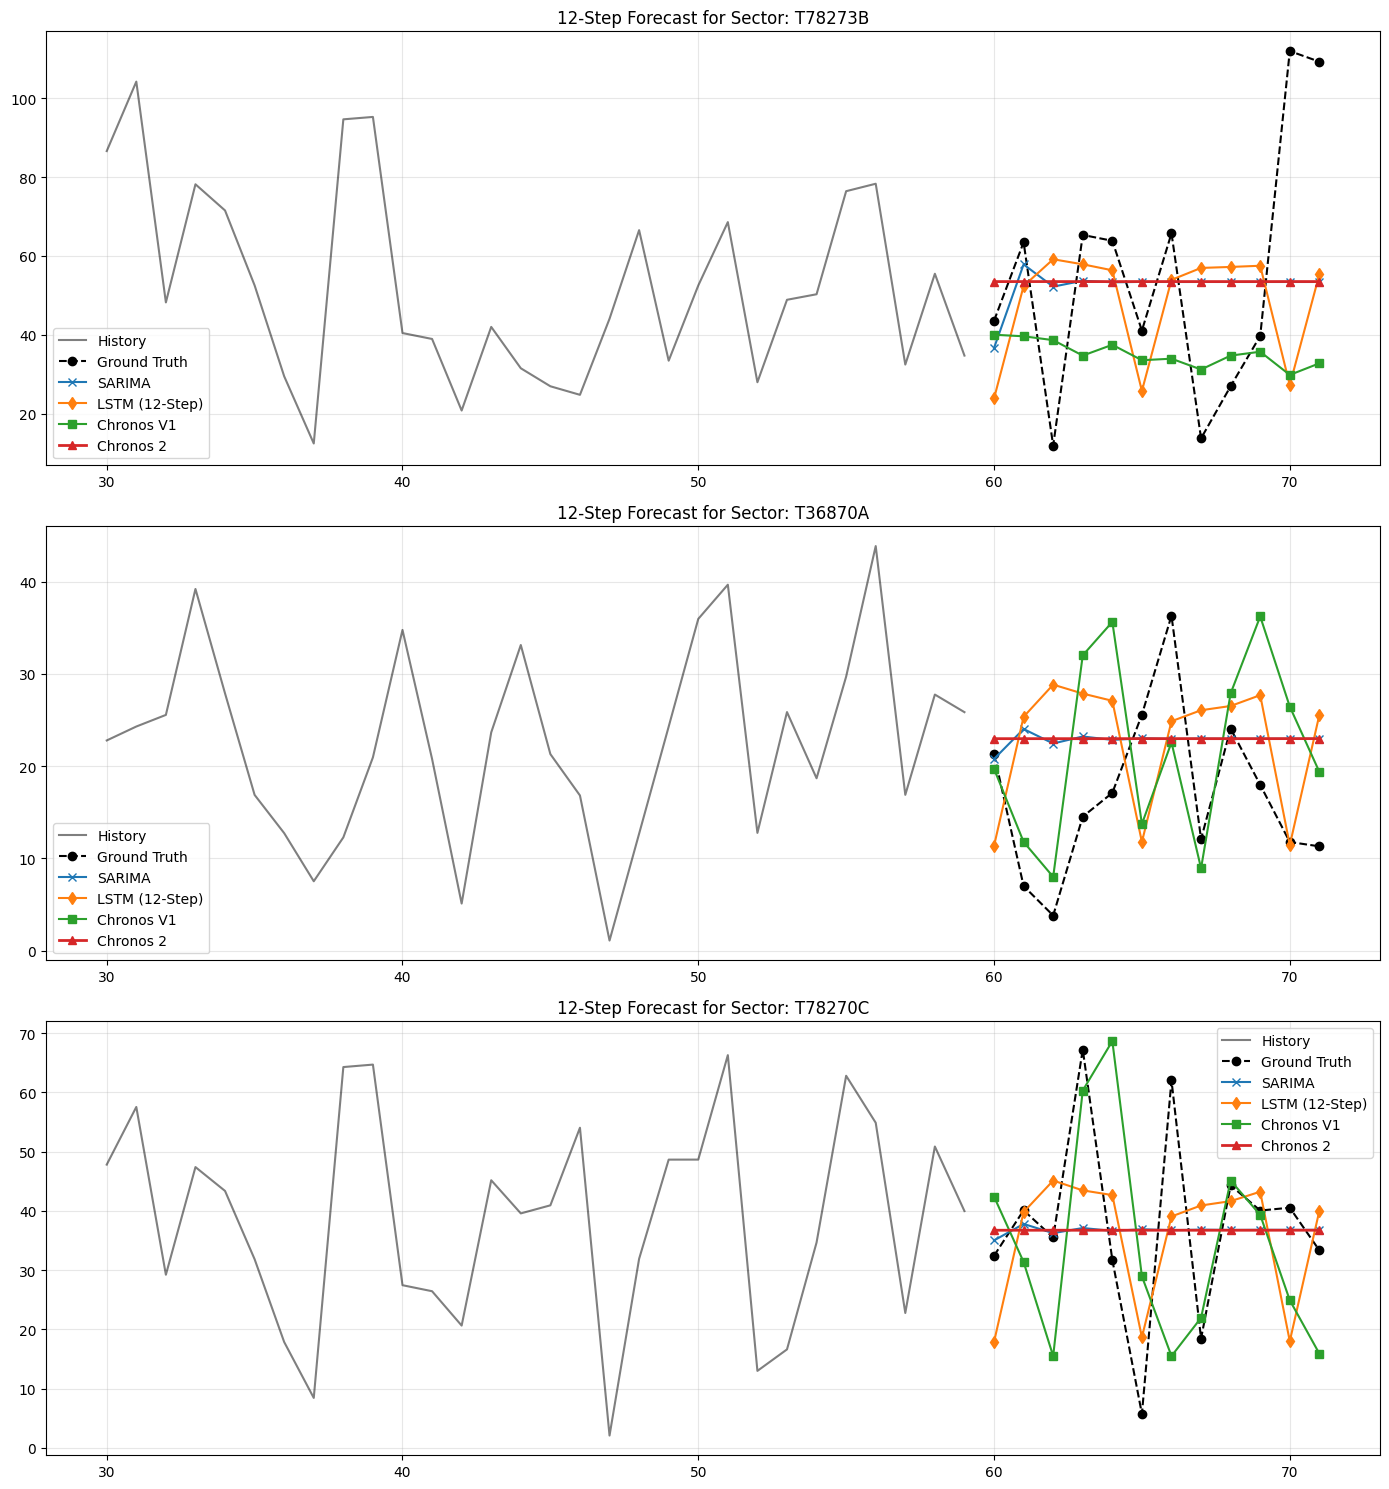

In [24]:
fig, axes = plt.subplots(3, 1, figsize=(14, 15))
for idx, sector in enumerate(sample_sectors):
    i = valid_sectors.index(sector)
    history = all_histories[i]
    actual = all_actuals[i]
    ax = axes[idx]
    x_hist, x_pred = np.arange(60), np.arange(60, 72)
    ax.plot(x_hist[30:], history[30:], color='black', label="History", alpha=0.5)
    ax.plot(x_pred, actual, marker='o', color='black', label="Ground Truth", linestyle='--')
    ax.plot(x_pred, sarima_preds_12_dict[sector], marker='x', label="SARIMA")
    ax.plot(x_pred, lstm_preds_12_dict[sector], marker='d', label="LSTM (12-Step)")
    ax.plot(x_pred, chronos_v1_preds_12['0.5'][i], marker='s', label="Chronos V1")
    ax.plot(x_pred, chronos_v2_preds_12['0.5'][i], marker='^', label="Chronos 2", linewidth=2)
    ax.set_title(f"12-Step Forecast for Sector: {sector}")
    ax.grid(alpha=0.3); ax.legend()
plt.tight_layout()
plt.show()

In [25]:
sarima_rmses_1, lstm_rmses_1, c_v1_rmses_1, c_v2_rmses_1 = [], [], [], []
sarima_pbl_1, lstm_pbl_1, c_v1_pbl_1, c_v2_pbl_1 = [], [], [], []
sarima_preds_1_dict, lstm_preds_1_dict = {}, {}

In [26]:
print("Evaluating 1-Step Forecasts...")
for i, sector in enumerate(tqdm(valid_sectors)):
    actual_1 = all_actuals[i][-1:] 
    history = all_histories[i]

    sr_1 = get_sarima_forecast(history, pred_length=1)
    s_pred_1 = sr_1['0.5']
    sarima_preds_1_dict[sector] = s_pred_1

    s_min, s_max = scalers[sector]
    lstm_in = 2 * (history - s_min) / (s_max - s_min) - 1 if s_max > s_min else history - s_min
    lstm_in_t = torch.tensor(lstm_in, dtype=torch.float32).unsqueeze(0).unsqueeze(-1).to(device)
    with torch.no_grad():
        lstm_out_scaled = lstm_model_1(lstm_in_t).cpu().numpy().flatten()
    lstm_pred_1 = ((lstm_out_scaled + 1) / 2) * (s_max - s_min) + s_min
    lstm_preds_1_dict[sector] = lstm_pred_1

    cv1_pred_1 = chronos_v1_preds_1['0.5'][i]
    cv2_pred_1 = chronos_v2_preds_1['0.5'][i]

    sm = calculate_metrics(actual_1, s_pred_1)
    lm = calculate_metrics(actual_1, lstm_pred_1)
    cv1m = calculate_metrics(actual_1, cv1_pred_1)
    cv2m = calculate_metrics(actual_1, cv2_pred_1)

    sarima_rmses_1.append(sm["RMSE"]); sarima_pbl_1.append(sm["Pinball_0.5"])
    lstm_rmses_1.append(lm["RMSE"]); lstm_pbl_1.append(lm["Pinball_0.5"])
    c_v1_rmses_1.append(cv1m["RMSE"]); c_v1_pbl_1.append(cv1m["Pinball_0.5"])
    c_v2_rmses_1.append(cv2m["RMSE"]); c_v2_pbl_1.append(cv2m["Pinball_0.5"])

Evaluating 1-Step Forecasts...


  0%|          | 0/86 [00:00<?, ?it/s]

  2%|▏         | 2/86 [00:00<00:11,  7.61it/s]

  3%|▎         | 3/86 [00:00<00:12,  6.54it/s]

  6%|▌         | 5/86 [00:00<00:12,  6.36it/s]

  7%|▋         | 6/86 [00:00<00:13,  6.00it/s]

... (69 outputs left out)

 97%|█████████▋| 83/86 [00:11<00:00,  7.94it/s]

 99%|█████████▉| 85/86 [00:12<00:00,  8.42it/s]

100%|██████████| 86/86 [00:12<00:00,  7.15it/s]

100%|██████████| 86/86 [00:12<00:00,  6.99it/s]

In [27]:
res_1 = pd.DataFrame({
    "Model": ["SARIMA", "LSTM", "Chronos V1", "Chronos 2"],
    "Avg RMSE (1-step)": [np.mean(sarima_rmses_1), np.mean(lstm_rmses_1), np.mean(c_v1_rmses_1), np.mean(c_v2_rmses_1)],
    "Avg PBL 50 (1-step)": [np.mean(sarima_pbl_1), np.mean(lstm_pbl_1), np.mean(c_v1_pbl_1), np.mean(c_v2_pbl_1)]
}).set_index("Model")
display(res_1)

,Avg RMSE (1-step),Avg PBL 50 (1-step)
Model,,
SARIMA,12.977569,6.488785
LSTM,27.063263,13.531631
Chronos V1,14.919609,7.459804
Chronos 2,11.510555,5.755277


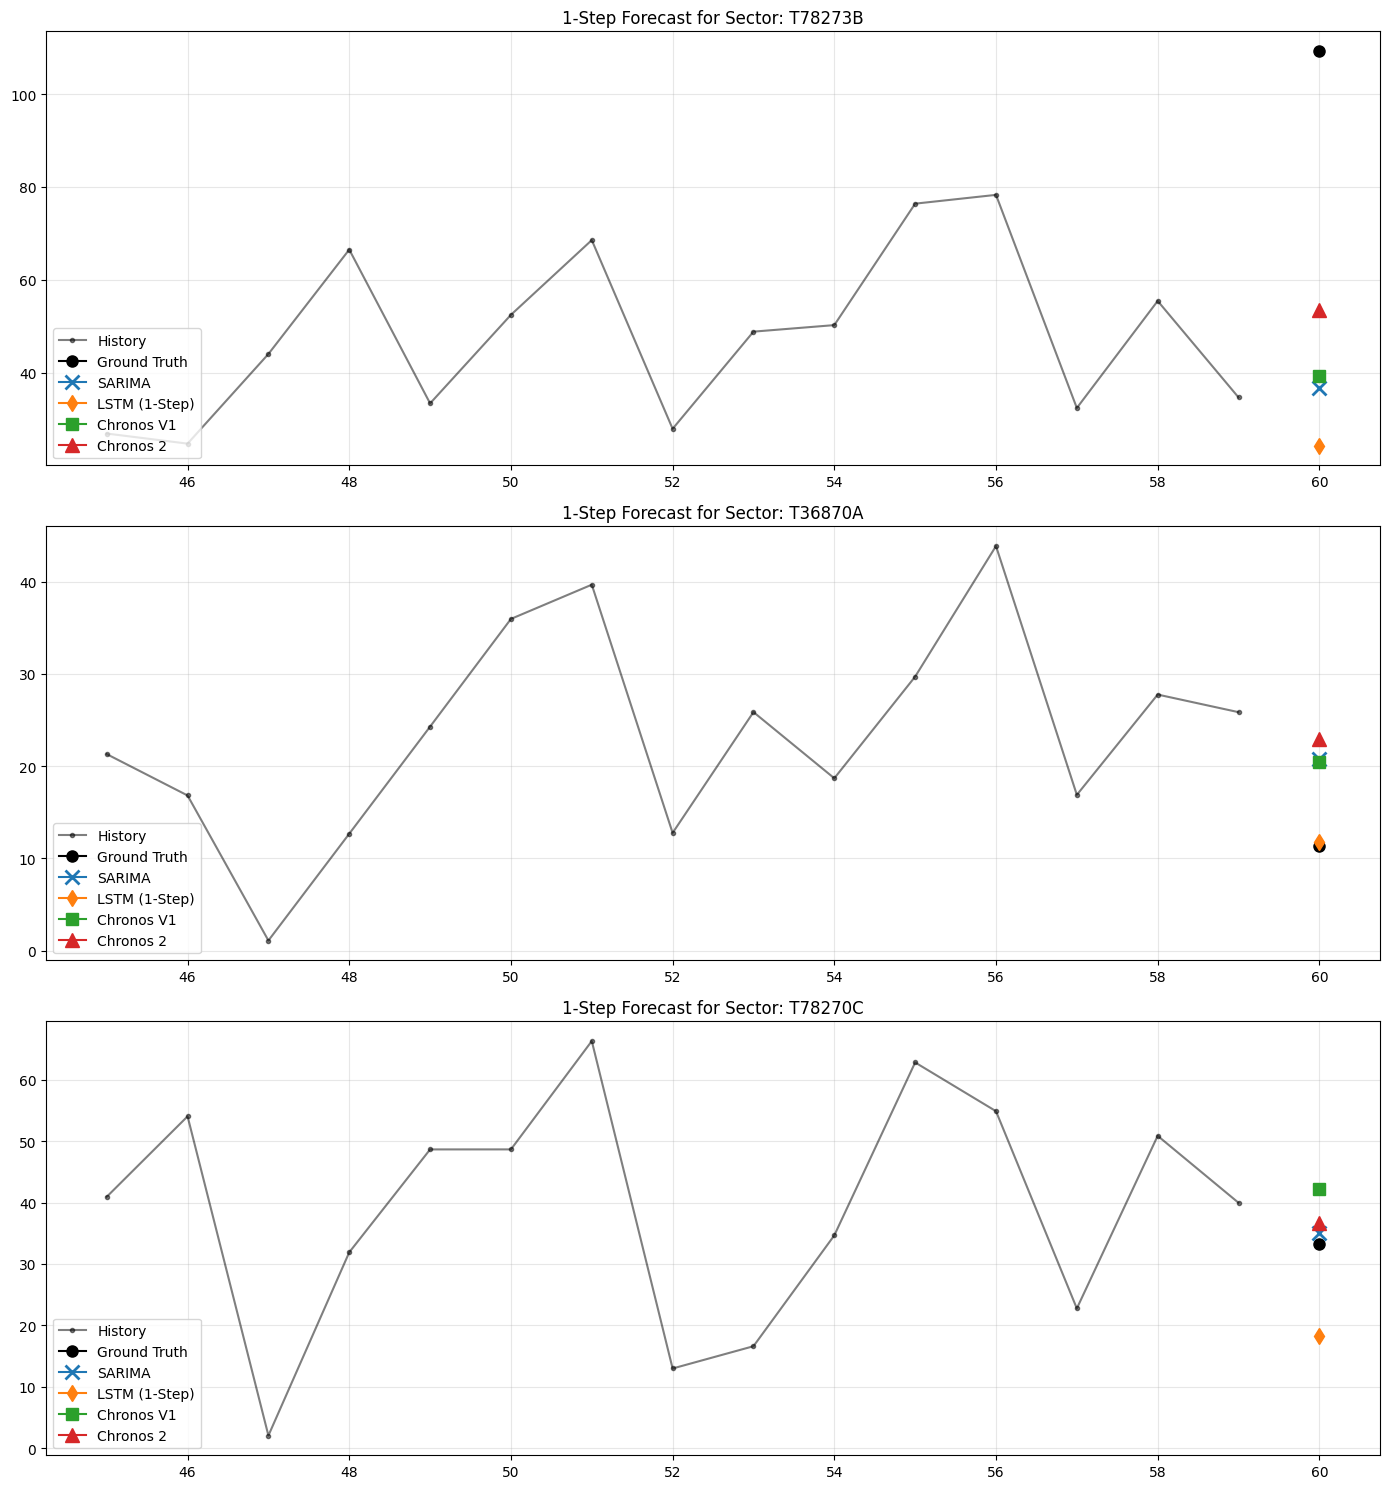

In [28]:
fig, axes = plt.subplots(3, 1, figsize=(14, 15))
for idx, sector in enumerate(sample_sectors):
    i = valid_sectors.index(sector)
    history = all_histories[i]
    actual_1 = all_actuals[i][-1:]

    ax = axes[idx]
    x_hist, x_pred = np.arange(60), np.arange(60, 61)
    ax.plot(x_hist[45:], history[45:], color='black', label="History", alpha=0.5, marker='.')
    ax.plot(x_pred, actual_1, marker='o', color='black', label="Ground Truth", markersize=8)
    ax.plot(x_pred, sarima_preds_1_dict[sector], marker='x', label="SARIMA", markersize=10, mew=2)
    ax.plot(x_pred, lstm_preds_1_dict[sector], marker='d', label="LSTM (1-Step)", markersize=8)
    ax.plot(x_pred, chronos_v1_preds_1['0.5'][i], marker='s', label="Chronos V1", markersize=8)
    ax.plot(x_pred, chronos_v2_preds_1['0.5'][i], marker='^', label="Chronos 2", markersize=10)

    ax.set_title(f"1-Step Forecast for Sector: {sector}")
    ax.grid(alpha=0.3); ax.legend(loc="lower left")
plt.tight_layout()
plt.show()